# Assess Performance

In [1]:
import pandas as pd
import numpy  as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from transformers    import AutoTokenizer, AutoModelForTokenClassification
from datasets        import load_dataset, Dataset
from seqeval.metrics import classification_report
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

/home/xgillard/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def tokenize_and_align_labels(model, tokenizer, dataset):
    """
    Crée le dataset correspondant au corpus complet tokenizé avec les labels qui sont correctement
    alignés sur les tokens. Ca renvoie un dataset avec les colonnes suivantes: 
    - input_ids
    - attention_mask
    - labels
    - tokens
    - tags
    """
    dataset = dataset.to_pandas()
    tokens  = [list(a) for a in dataset['tokens']]
    # on commence par tout tokenizer en batch
    max_seq_len= tokenizer.model_max_length
    tokenized  = tokenizer(
        tokens, 
        is_split_into_words=True,
        padding=True, 
        truncation=True,
        max_length=max_seq_len,
        return_overflowing_tokens=True,
    )
    # on aligne les labels avec les tokens dans les différentes séquences qui découpent le texte
    tokids = []
    labels = []
    amasks = []
    tokens = []
    classes= []
    for i, token_ids in enumerate(tokenized['input_ids']):
        sample_id  = tokenized['overflow_to_sample_mapping'][i]
        encoding   = tokenized.encodings[i]
        word_ids   = encoding.word_ids
        decoded    = [ tokenizer.convert_ids_to_tokens(tid) for tid in token_ids ]
        labelclass = [ dataset.iloc[sample_id]['labels'][w] if w is not None else 'IGN' for w in word_ids ]
        # fix les troncatures du tokenizer
        for k,lk in enumerate(labelclass):
            if k == 0:
                continue
            if lk.startswith('I-') and (labelclass[k-1] in ['O', 'IGN']):
                labelclass[k] = 'B-' + labelclass[k][2:]
        # on marque tous les sous mots comme étant IGN
        for k,wid in enumerate(word_ids):
            if k == 0:
                continue
            if wid == word_ids[k-1]:
                labelclass[k] = 'IGN'
        # on construit la liste d'id pour les labels
        labelids   = [ model.config.label2id[l] for l in labelclass ]
        amasks .append(tokenized['attention_mask'][i])
        tokens .append(decoded)
        tokids .append(token_ids)
        classes.append(labelclass)
        labels .append(labelids)
    #
    return Dataset.from_pandas(pd.DataFrame({'input_ids': tokids, 'attention_mask': amasks, 'tokens': tokens,'tags': classes, 'labels': labels}))

def align_and_filter(preds, grounds, errors):
    '''
    Renvoie un tuple comprenant 2 list[list[str]] qui sont les prédictions et la ground truth
    de sorte qu'ils soient filtrés pour ignorer les labels qui sont 'IGN'
    '''
    predictions = []
    ground_truth= []
    token_error = []
    
    for ps, gs,es in zip(preds,grounds, errors):
        pred   = []
        ground = []
        error  = []
    
        for p,g,e in zip(ps, gs, es):
            if g != 'IGN':
                pred.append(p)
                ground.append(g)
                error.append(e)
        predictions.append(pred)
        ground_truth.append(ground)
        token_error.append(error)
    #
    return predictions, ground_truth, token_error

@torch.no_grad()
def process_one_batch(model, batch, device=DEVICE):
    '''
    Renvoie un tuple comprenant 2 list[list[str]] qui sont les prédictions et la ground truth
    et une list[list[float]] qui comprend l'erreur par token.
    '''
    model     = model.to(device).eval()
    id2label  = model.config.id2label
    input_ids = torch.tensor(batch['input_ids'], dtype=torch.int, device=device)
    attn_mask = torch.tensor(batch['attention_mask'], dtype=torch.int, device=device)
    logits    = model(input_ids=input_ids, attention_mask=attn_mask).logits
    labels    = torch.tensor(batch['labels']).to(device)
    pertoken  = (-1, len(id2label))
    error     = F.cross_entropy(logits.view(pertoken), labels.view(-1), reduction='none') 
    predicted = logits.argmax(-1).detach().cpu().numpy().tolist()
    predicted = [[id2label[p] for p in preds] for preds in predicted]
    error     = error.view(logits.shape[:2]).tolist()
    gt        = batch['tags']
    return predicted, gt, error

In [3]:
def explode_it_all(ds):
    df = ds.to_pandas()
    
    df2 = (df[['tokens', 'tags']]).explode(['tokens', 'tags'])
    df2 = df2[df2['tags'] != 'IGN']
    df3 = (df[['labels', 'predictions', 'error']]).explode(['labels', 'predictions', 'error'])
    
    return pd.concat([df2, df3], axis=1)

def most_wrong(df):
    return (df.groupby('tokens')[['error']]
         .agg(['count', 'mean', 'sum'])
         .droplevel(0, axis=1)
         .sort_values(by='mean', ascending=False)
    ).head(10)

def plot_confusion_matrix(predictions, ground_truth, labels):
    C = len(labels)
    confusion = confusion_matrix(ground_truth, predictions, labels=labels, normalize='true')
    fig, ax = plt.subplots(figsize=(C, C))
    display = ConfusionMatrixDisplay(confusion_matrix=confusion, display_labels=labels)
    display.plot(cmap="Blues", values_format=".2f", ax=ax, colorbar=False)
    plt.show()

def error_analysis(model, ds):
    cat = [v for v in model.config.id2label.values() if v != 'IGN']
    df  = explode_it_all(ds)

    print("========== HIGHEST ERRORS ======================")
    print(most_wrong(df))
    print("========== CONFUSION MATRIX ====================")
    plot_confusion_matrix(df['predictions'], df['labels'], cat)

def assess_performance(name, model, ds):
    def dataset_batch_processor(batch):
        p, g, e = process_one_batch(model, batch)
        p, g, e = align_and_filter(p, g, e)
        return {'predictions': p, 'labels': g, 'error': e}
    
    ds = ds.map(dataset_batch_processor, batched=True, batch_size=100)

    print(f"********* {name} ******************************")
    print("########## PERFORMANCE REPORT ###################")
    print(classification_report(ds['predictions'], ds['labels']))
    print("########## ERROR ANALYSIS #######################")
    error_analysis(model, ds)
    return ds


Map: 100%|█████████████████████████████████████████████████████████████████████| 195/195 [00:12<00:00, 15.87 examples/s]


********* BRABRANT-XVII-NER ******************************
########## PERFORMANCE REPORT ###################
              precision    recall  f1-score   support

        DATE       0.47      0.48      0.48        77
         LOC       0.79      0.72      0.75       632
        PERS       0.90      0.89      0.89       824

   micro avg       0.83      0.80      0.81      1533
   macro avg       0.72      0.70      0.71      1533
weighted avg       0.83      0.80      0.81      1533

########## ERROR ANALYSIS #######################
========== HIGHEST ERRORS ======================
         count      mean        sum
tokens                             
▁hulle       1  9.518271   9.518271
▁steden      1  9.282433   9.282433
▁hoy         2  8.022853  16.045705
▁conte       1  7.916607   7.916607
▁lance       1  6.932829   6.932829
▁archi       1  6.912547   6.912547
▁32          1  6.059977   6.059977
▁marche      1  5.815635   5.815635
▁stil        1  5.776609   5.776609
▁ut          1 

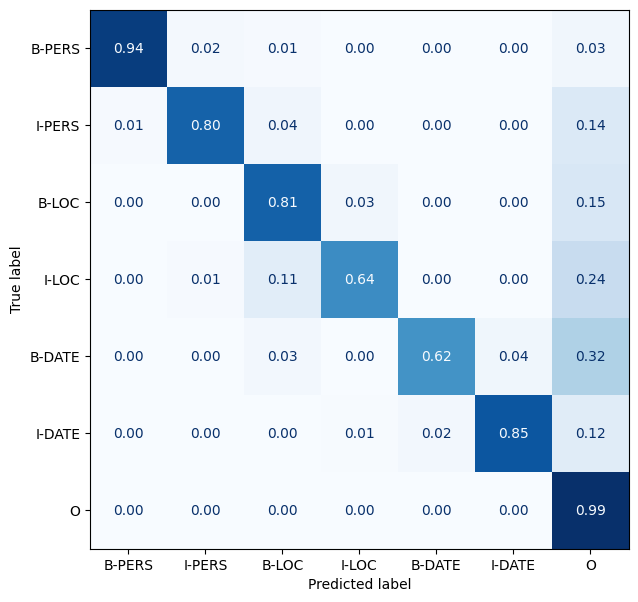

In [4]:
checkpt   = "xaviergillard/brabrant-xvii-ner"
tokenizer = AutoTokenizer.from_pretrained(checkpt)
model     = AutoModelForTokenClassification.from_pretrained(checkpt, device_map="auto")
#
valid     = tokenize_and_align_labels(model, tokenizer, load_dataset("xaviergillard/brabant-xvii-ner")['valid'])
ds2       = assess_performance("BRABRANT-XVII-NER", model, valid)